# Practical 19: Logistic Regression, KNN and SVM

**Aim:** To implement Logistic Regression, KNN and SVM on the Breast Cancer dataset and compare their accuracy and confusion matrices.

**Kaggle Dataset:** [Breast Cancer Wisconsin (Diagnostic)](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data)

Download `data.csv` and keep it in the same folder as this notebook.

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load dataset
data = pd.read_csv('data.csv')
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
# Select input and output
X = data.drop(['id', 'diagnosis', 'Unnamed: 32'], axis=1)
y = data['diagnosis']

In [4]:
# Split dataset
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
# Feature scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [6]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
LR = LogisticRegression(max_iter=1000)
LR.fit(X_train, y_train)
y_pred_lr = LR.predict(X_test)
print('Logistic Regression Accuracy:', LR.score(X_test, y_test) * 100)

Logistic Regression Accuracy: 97.36842105263158


In [7]:
# KNN Classifier
from sklearn.neighbors import KNeighborsClassifier
KNN = KNeighborsClassifier(n_neighbors=5)
KNN.fit(X_train, y_train)
y_pred_knn = KNN.predict(X_test)
print('KNN Accuracy:', KNN.score(X_test, y_test) * 100)

KNN Accuracy: 94.73684210526315


In [8]:
# SVM Classifier
from sklearn.svm import SVC
SVM = SVC(kernel='linear')
SVM.fit(X_train, y_train)
y_pred_svm = SVM.predict(X_test)
print('SVM Accuracy:', SVM.score(X_test, y_test) * 100)

SVM Accuracy: 95.6140350877193


Accuracy: [97.36842105263158, 94.73684210526315, 95.6140350877193]


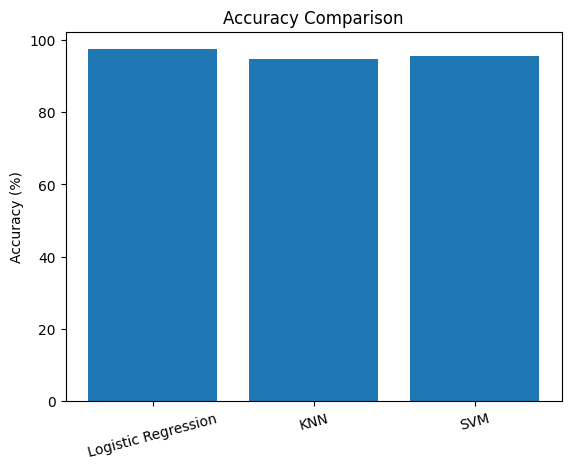

In [9]:
# Compare accuracy
from sklearn.metrics import accuracy_score
accuracy = [
    accuracy_score(y_test, y_pred_lr) * 100,
    accuracy_score(y_test, y_pred_knn) * 100,
    accuracy_score(y_test, y_pred_svm) * 100
]
models = ['Logistic Regression', 'KNN', 'SVM']
print('Accuracy:', accuracy)

plt.bar(models, accuracy)
plt.ylabel('Accuracy (%)')
plt.title('Accuracy Comparison')
plt.xticks(rotation=15)
plt.show()

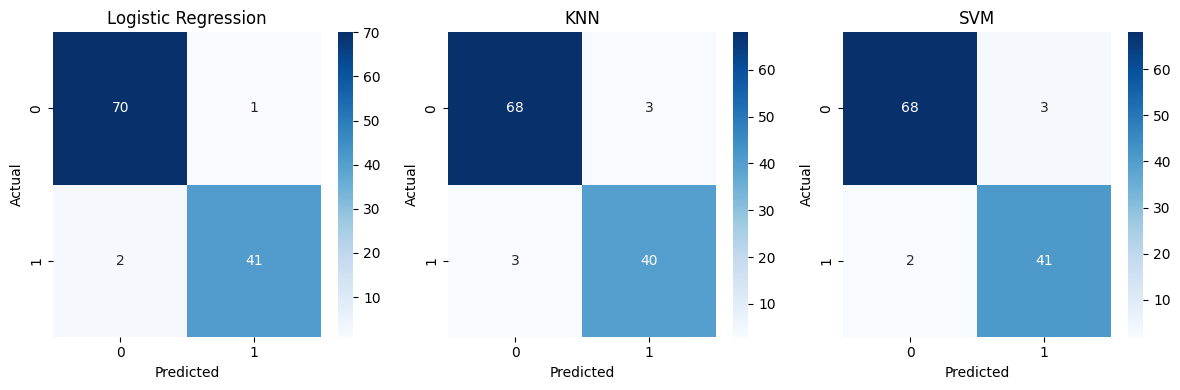

In [10]:
# Confusion matrices
from sklearn.metrics import confusion_matrix
cm1 = confusion_matrix(y_test, y_pred_lr, labels=['B', 'M'])
cm2 = confusion_matrix(y_test, y_pred_knn, labels=['B', 'M'])
cm3 = confusion_matrix(y_test, y_pred_svm, labels=['B', 'M'])

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues')
plt.title('Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.subplot(1, 3, 2)
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues')
plt.title('KNN')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.subplot(1, 3, 3)
sns.heatmap(cm3, annot=True, fmt='d', cmap='Blues')
plt.title('SVM')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.tight_layout()
plt.show()

## Conclusion

Logistic Regression, KNN and SVM classifiers were implemented on the Breast Cancer dataset. Their accuracy and confusion matrices were compared.